# Interpolation Method Analysis (Matsuoka 1984)

This notebook compares four spatial interpolation methods for water quality data (Dissolved Oxygen), following the principles from the Matsuoka (1984) report:
1. **Moving Average (WT):** Inverse Distance / Gaussian Weighting
2. **Spline (SP):** Radial Basis Function interpolation minimizing curvature
3. **Kriging (KG):** Ordinary Kriging using `pykrige`
4. **Convective Diffusion (CD):** Iterative numerical diffusion bounded by grid geometry

Methods are evaluated using **Leave-One-Out Cross-Validation (LOOCV)** as specified in the report.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from pathlib import Path
import sys
from scipy.spatial.distance import cdist
from scipy.interpolate import Rbf
from scipy.ndimage import convolve
from pykrige.ok import OrdinaryKriging
import warnings
warnings.filterwarnings('ignore')

# Ensure local scripts are importable
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths

sns.set_style("whitegrid")


## 1. Load Data
We load the `yearly_do_df`, distance matrix, and decorrelation results from the seasonal pipeline (e.g., Summer Bottom).


In [2]:
subset_dir = str(ProjectPaths.get_subset_dir('Summer', 'bottom'))
subset_path = Path(subset_dir)

# 1. Yearly DO Data
yearly_do_df = pd.read_csv(subset_path / "yearly_do_df.csv", index_col=0)
yearly_do_df.index = yearly_do_df.index.astype(str).str.zfill(8)

# 2. Distance Matrix (km)
dist_matrix_km = pd.read_csv(ProjectPaths.PROCESSED_DATA_DIR / "dist_matrix_km.csv", index_col=0)
dist_matrix_km.index = dist_matrix_km.index.astype(str).str.zfill(8)
dist_matrix_km.columns = dist_matrix_km.columns.astype(str).str.zfill(8)

# 3. Decorrelation Scale Results
decorrelation_df = pd.read_csv(subset_path / "stations_decorrelation_scale.csv", index_col=0)
decorrelation_df.index = decorrelation_df.index.astype(str).str.zfill(8)

# 4. Station coordinates
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)
station_locs = merged_gdf.drop_duplicates('zettaicode').set_index('zettaicode')
station_locs = station_locs.loc[yearly_do_df.index]
station_locs_proj = station_locs.to_crs(epsg=32653) # UTM Zone 53N for meters
station_coords = pd.DataFrame({
    'x': station_locs_proj.geometry.x,
    'y': station_locs_proj.geometry.y
}, index=station_locs_proj.index)

print(f"Loaded Yearly DO Data: {yearly_do_df.shape}")


Loaded Yearly DO Data: (124, 41)


## 2. Implement Interpolation Methods Definition

Here we define wrappers for each method to predict a missing value for a target station, given coordinates and values of surrounding stations.


In [3]:
def predict_wt(target_loc, known_locs, known_values, scale=30.0):
    """ Moving Average (WT) using Gaussian inverse distance weighting. """
    dist = cdist([target_loc], known_locs)[0]
    dist_km = dist / 1000.0
    weights = np.exp(-(dist_km**2) / (2 * scale**2))
    if np.sum(weights) == 0:
        return np.nan
    return np.sum(weights * known_values) / np.sum(weights)

def predict_sp(target_loc, known_locs, known_values):
    """ Spline (SP) using Radial Basis Functions (multiquadric). """
    try:
        rbf = Rbf(known_locs[:, 0], known_locs[:, 1], known_values, function='multiquadric', smooth=1.0)
        return rbf(target_loc[0], target_loc[1])
    except:
        return np.nan

def predict_kg(target_loc, known_locs, known_values):
    """ Kriging (KG) using ordinary kriging from pykrige. """
    try:
        # Convert coords to km to avoid float scaling issues in variogram fit
        ok = OrdinaryKriging(
            known_locs[:, 0] / 1000.0, 
            known_locs[:, 1] / 1000.0, 
            known_values, 
            variogram_model='spherical',
            verbose=False, enable_plotting=False
        )
        z, _ = ok.execute('points', np.array([target_loc[0]/1000.0]), np.array([target_loc[1]/1000.0]))
        return z[0]
    except:
        return np.nan

def predict_cd(target_loc, known_locs, known_values):
    """ 
    Simplified Convective Diffusion (CD): numerical diffusion solution 
    This creates a local grid, sets the known boundaries, diffuses, and extracts target point.
    """
    try:
        # Create a bounding box grid around the points
        all_x = np.append(known_locs[:, 0], target_loc[0])
        all_y = np.append(known_locs[:, 1], target_loc[1])
        min_x, max_x = np.min(all_x), np.max(all_x)
        min_y, max_y = np.min(all_y), np.max(all_y)
        
        # Define grid bounds (2km buffer) and spacing (1km)
        grid_size = 1000.0 
        x_grid = np.arange(min_x - 2000, max_x + 2000, grid_size)
        y_grid = np.arange(min_y - 2000, max_y + 2000, grid_size)
        
        # If grid is too small, fallback
        if len(x_grid) < 3 or len(y_grid) < 3:
            return np.mean(known_values)
            
        Z = np.full((len(y_grid), len(x_grid)), np.nan)
        mask_known = np.zeros_like(Z, dtype=bool)
        
        # Map known points to grid
        for i_pt in range(len(known_locs)):
            xc, yc = known_locs[i_pt]
            ix = int((xc - x_grid[0]) / grid_size)
            iy = int((yc - y_grid[0]) / grid_size)
            if 0 <= ix < len(x_grid) and 0 <= iy < len(y_grid):
                Z[iy, ix] = known_values[i_pt]
                mask_known[iy, ix] = True
        
        # Fill NaNs with mean to start
        mean_val = np.nanmean(known_values)
        Z[~mask_known] = mean_val
        
        # Diffuse
        kernel = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]]) / 4.0
        for _ in range(300): # Iterations
            Z_new = convolve(Z, kernel, mode='reflect')
            Z_new[mask_known] = Z[mask_known]
            Z = Z_new
            
        # Extract target point
        tx = int((target_loc[0] - x_grid[0]) / grid_size)
        ty = int((target_loc[1] - y_grid[0]) / grid_size)
        tx = np.clip(tx, 0, len(x_grid)-1)
        ty = np.clip(ty, 0, len(y_grid)-1)
        return Z[ty, tx]
    except Exception as e:
        return np.nan


## 3. Leave-One-Out Cross Validation (LOOCV)

Iterate over years. For each year, get stations with valid DO. Iteratively remove one station and predict using the rest.


In [4]:
results = []
years_to_process = yearly_do_df.columns[:5] # Limit to 5 years for speed in development

for year in years_to_process:
    year_data = yearly_do_df[year].dropna()
    valid_stations = list(set(year_data.index) & set(station_coords.index))
    
    # Needs enough stations to do kriging/spline
    if len(valid_stations) < 10:
        continue
        
    print(f"Processing Year: {year} ({len(valid_stations)} stations)")
    
    for i, target_station in enumerate(valid_stations):
        # The true value
        true_val = year_data.loc[target_station]
        target_loc = station_coords.loc[target_station].values
        
        # Available data
        train_stations = [s for s in valid_stations if s != target_station]
        train_locs = station_coords.loc[train_stations].values
        train_vals = year_data.loc[train_stations].values
        
        # Default target WT scale from Decorr Analysis, fallback to 30km
        try:
            wt_scale = decorrelation_df.loc[target_station, 'Decorrelation_Scale_km']
            if pd.isna(wt_scale) or wt_scale <= 0: wt_scale = 30.0
        except:
            wt_scale = 30.0
            
        # Predict
        pred_wt = predict_wt(target_loc, train_locs, train_vals, scale=wt_scale)
        pred_sp = predict_sp(target_loc, train_locs, train_vals)
        pred_kg = predict_kg(target_loc, train_locs, train_vals)
        pred_cd = predict_cd(target_loc, train_locs, train_vals)
        
        results.append({
            'Year': year,
            'Station': target_station,
            'True_DO': true_val,
            'Pred_WT': pred_wt,
            'Pred_SP': pred_sp,
            'Pred_KG': pred_kg,
            'Pred_CD': pred_cd
        })

loocv_results = pd.DataFrame(results)
print("Finished LOOCV.")


Processing Year: 1982 (124 stations)
Processing Year: 1984 (124 stations)
Processing Year: 1985 (124 stations)
Processing Year: 1986 (124 stations)
Processing Year: 1987 (122 stations)
Finished LOOCV.


## 4. Evaluation and Visualization

Calculate MAE and RMSE for each method.


,MAE,RMSE,Valid_N
Method,,,
WT,0.647941,0.967628,573
SP,0.612282,0.918952,618
KG,0.614399,0.925108,618
CD,0.775649,1.099159,618


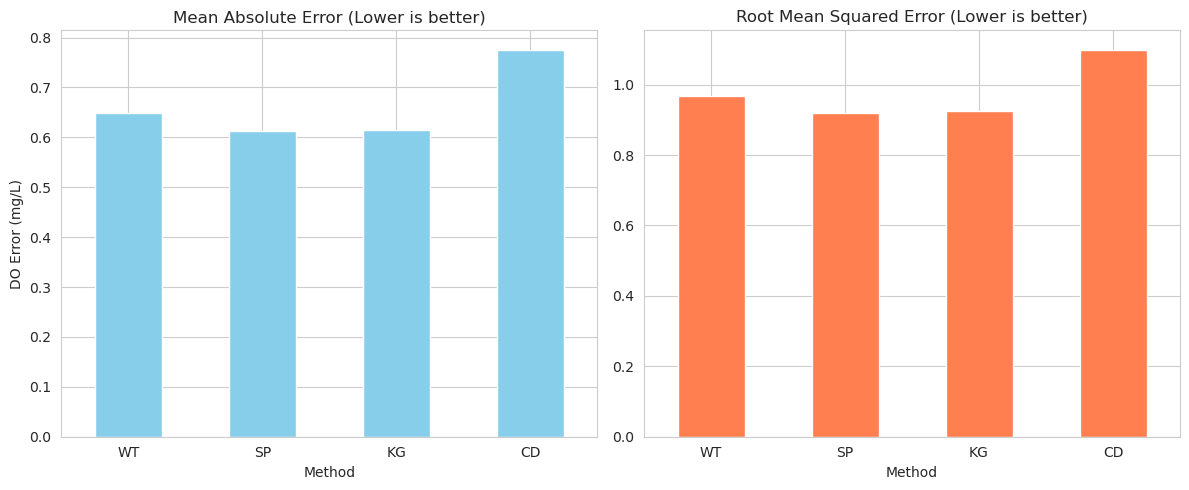

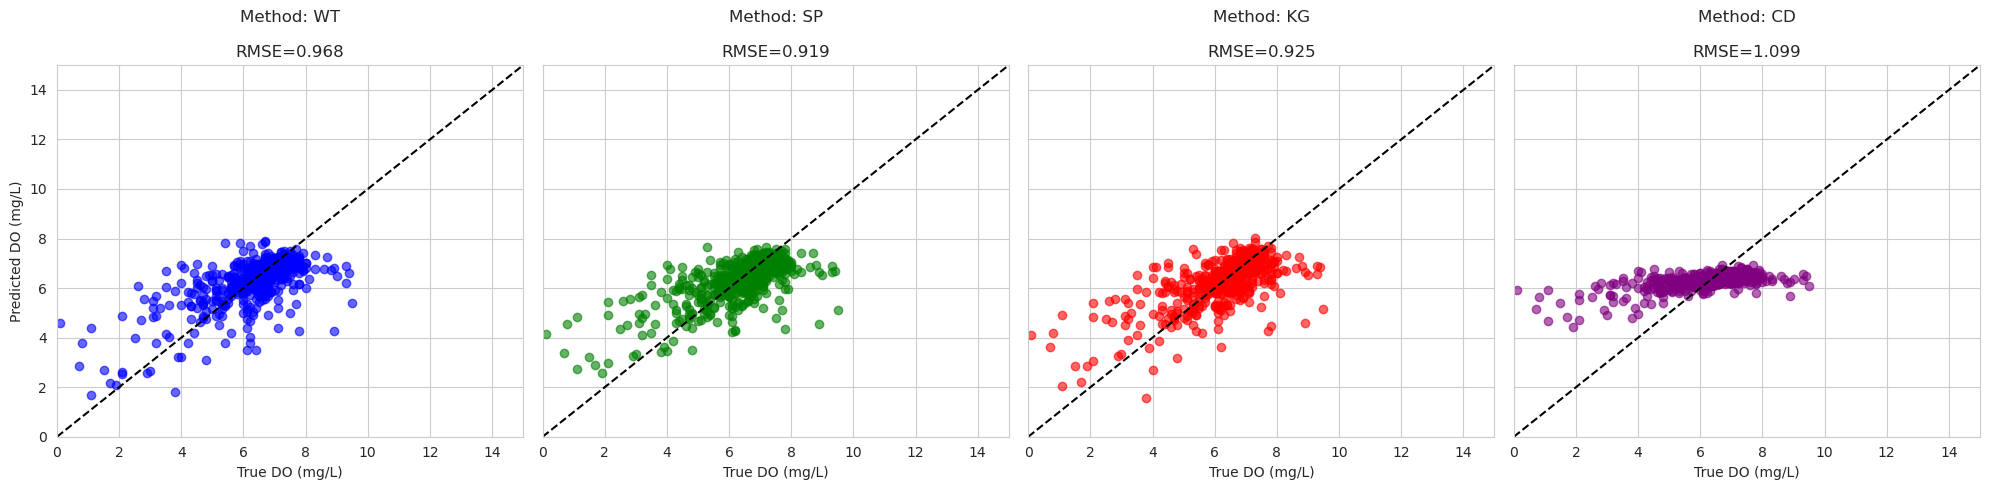

In [5]:
# Calculate errors
loocv_results['Err_WT'] = loocv_results['Pred_WT'] - loocv_results['True_DO']
loocv_results['Err_SP'] = loocv_results['Pred_SP'] - loocv_results['True_DO']
loocv_results['Err_KG'] = loocv_results['Pred_KG'] - loocv_results['True_DO']
loocv_results['Err_CD'] = loocv_results['Pred_CD'] - loocv_results['True_DO']

metrics = []
for m in ['WT', 'SP', 'KG', 'CD']:
    errs = loocv_results[f'Err_{m}'].dropna()
    mae = np.mean(np.abs(errs))
    rmse = np.sqrt(np.mean(errs**2))
    metrics.append({'Method': m, 'MAE': mae, 'RMSE': rmse, 'Valid_N': len(errs)})

metrics_df = pd.DataFrame(metrics).set_index('Method')
display(metrics_df)

# Plot Error Bars
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
metrics_df[['MAE']].plot(kind='bar', ax=axes[0], color='skyblue', legend=False)
axes[0].set_title('Mean Absolute Error (Lower is better)')
axes[0].set_ylabel('DO Error (mg/L)')
axes[0].tick_params(axis='x', rotation=0)

metrics_df[['RMSE']].plot(kind='bar', ax=axes[1], color='coral', legend=False)
axes[1].set_title('Root Mean Squared Error (Lower is better)')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

# Scatter Error Plots
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)
methods = ['WT', 'SP', 'KG', 'CD']
colors = ['blue', 'green', 'red', 'purple']

for i, m in enumerate(methods):
    df_plot = loocv_results.dropna(subset=[f'Pred_{m}'])
    axes[i].scatter(df_plot['True_DO'], df_plot[f'Pred_{m}'], alpha=0.6, color=colors[i])
    axes[i].plot([0, 15], [0, 15], 'k--', lw=1.5) # 1:1 line
    axes[i].set_title(f"Method: {m}\n\nRMSE={metrics_df.loc[m, 'RMSE']:.3f}", fontsize=12)
    axes[i].set_xlabel('True DO (mg/L)')
    if i == 0:
        axes[i].set_ylabel('Predicted DO (mg/L)')

plt.xlim(0, 15)
plt.ylim(0, 15)
plt.tight_layout()
plt.show()


## 5. Visualizing Spatial Coverage Examples
We generate a dense grid over a subset of the sea for a given year to see what the generated surfaces look like.


Predicting grid for WT...
Predicting grid for SP...
Predicting grid for KG...
Predicting grid for CD...


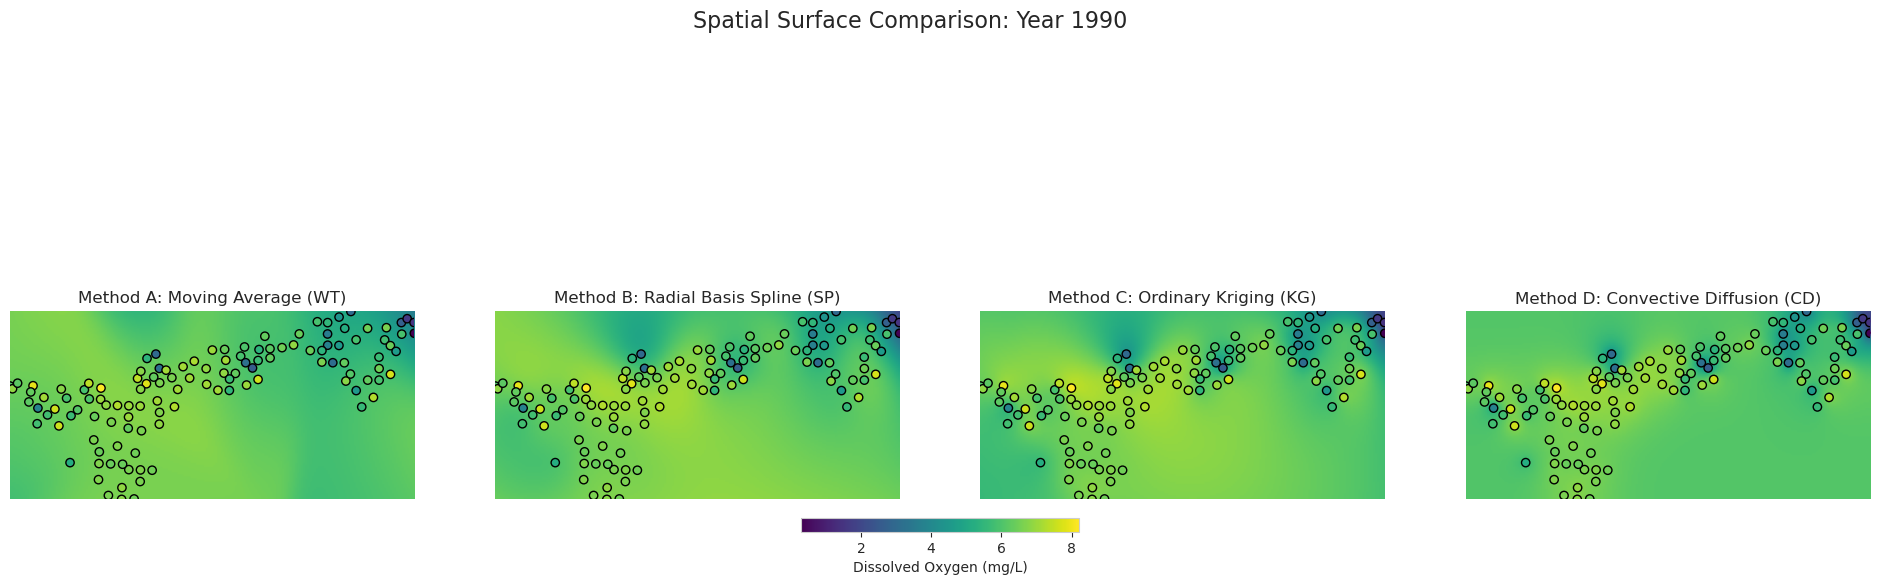

In [6]:
# Let's map a reference year: 1990
test_year = '1990'
year_data = yearly_do_df[test_year].dropna()
valid_stations = list(set(year_data.index) & set(station_coords.index))

train_locs = station_coords.loc[valid_stations].values
train_vals = year_data.loc[valid_stations].values

# Generate bounding box grid
min_x, max_x = np.min(train_locs[:, 0]), np.max(train_locs[:, 0])
min_y, max_y = np.min(train_locs[:, 1]), np.max(train_locs[:, 1])

grid_res = 2000.0 # 2km resolution
grid_x = np.arange(min_x, max_x, grid_res)
grid_y = np.arange(min_y, max_y, grid_res)
X, Y = np.meshgrid(grid_x, grid_y)

# Flatten grid to points
grid_pts = np.vstack((X.flatten(), Y.flatten())).T

print("Predicting grid for WT...")
grid_pred_wt = np.array([predict_wt(pt, train_locs, train_vals, scale=30.0) for pt in grid_pts])
print("Predicting grid for SP...")
grid_pred_sp = np.array([predict_sp(pt, train_locs, train_vals) for pt in grid_pts])
print("Predicting grid for KG...")
try:
    ok = OrdinaryKriging(train_locs[:, 0]/1000.0, train_locs[:, 1]/1000.0, train_vals, variogram_model='spherical')
    z_kg, _ = ok.execute('grid', grid_x/1000.0, grid_y/1000.0)
    grid_pred_kg = z_kg.data.flatten()
except:
    grid_pred_kg = np.full(grid_pts.shape[0], np.nan)
print("Predicting grid for CD...")
# CD method is expensive point by point, so we just run the diffusion once on the main grid
try:
    Z_cd = np.full(X.shape, np.nan)
    mask_known = np.zeros_like(Z_cd, dtype=bool)
    for i_pt in range(len(train_locs)):
        xc, yc = train_locs[i_pt]
        ix = int((xc - grid_x[0]) / grid_res)
        iy = int((yc - grid_y[0]) / grid_res)
        if 0 <= ix < X.shape[1] and 0 <= iy < X.shape[0]:
            Z_cd[iy, ix] = train_vals[i_pt]
            mask_known[iy, ix] = True
            
    Z_cd[~mask_known] = np.mean(train_vals)
    kernel = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]]) / 4.0
    for _ in range(500):
        Z_new = convolve(Z_cd, kernel, mode='reflect')
        Z_new[mask_known] = Z_cd[mask_known]
        Z_cd = Z_new
    grid_pred_cd = Z_cd.flatten()
except:
    grid_pred_cd = np.full(grid_pts.shape[0], np.nan)

# Reshape back 
Z_wt = grid_pred_wt.reshape(X.shape)
Z_sp = grid_pred_sp.reshape(X.shape)
Z_kg = grid_pred_kg.reshape(X.shape)
Z_cd = grid_pred_cd.reshape(X.shape)

# Plot
fig, axes = plt.subplots(1, 4, figsize=(24, 6), sharex=True, sharey=True)

vmin, vmax = np.min(train_vals), np.max(train_vals)
cmap = plt.cm.viridis

im0 = axes[0].imshow(Z_wt, origin='lower', extent=[min_x, max_x, min_y, max_y], cmap=cmap, vmin=vmin, vmax=vmax)
axes[0].scatter(train_locs[:, 0], train_locs[:, 1], c=train_vals, edgecolors='k', cmap=cmap, vmin=vmin, vmax=vmax)
axes[0].set_title('Method A: Moving Average (WT)')

im1 = axes[1].imshow(Z_sp, origin='lower', extent=[min_x, max_x, min_y, max_y], cmap=cmap, vmin=vmin, vmax=vmax)
axes[1].scatter(train_locs[:, 0], train_locs[:, 1], c=train_vals, edgecolors='k', cmap=cmap, vmin=vmin, vmax=vmax)
axes[1].set_title('Method B: Radial Basis Spline (SP)')

im2 = axes[2].imshow(Z_kg, origin='lower', extent=[min_x, max_x, min_y, max_y], cmap=cmap, vmin=vmin, vmax=vmax)
axes[2].scatter(train_locs[:, 0], train_locs[:, 1], c=train_vals, edgecolors='k', cmap=cmap, vmin=vmin, vmax=vmax)
axes[2].set_title('Method C: Ordinary Kriging (KG)')

im3 = axes[3].imshow(Z_cd, origin='lower', extent=[min_x, max_x, min_y, max_y], cmap=cmap, vmin=vmin, vmax=vmax)
axes[3].scatter(train_locs[:, 0], train_locs[:, 1], c=train_vals, edgecolors='k', cmap=cmap, vmin=vmin, vmax=vmax)
axes[3].set_title('Method D: Convective Diffusion (CD)')

for ax in axes:
    ax.axis('off')
    
fig.colorbar(im0, ax=axes.ravel().tolist(), orientation='horizontal', fraction=0.03, pad=0.04, label='Dissolved Oxygen (mg/L)')
plt.suptitle(f'Spatial Surface Comparison: Year {test_year}', fontsize=16)
plt.show()
